<a href="https://colab.research.google.com/github/ShamGaneshan2008/.ipynb-files-/blob/main/NeuroScope_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

import numpy as np
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

torch.manual_seed(42)
np.random.seed(42)

In [2]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Image shape:", train_dataset[0][0].shape)
print("Example label:", train_dataset[0][1])


100%|██████████| 9.91M/9.91M [00:00<00:00, 57.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.65MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 13.5MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.94MB/s]


Training images: 60000
Testing images: 10000
Image shape: torch.Size([1, 28, 28])
Example label: 5


In [3]:

# NEUROSCOPE AI
# Cell 4: Prepare data loaders

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)


Training batches: 938
Testing batches: 157
Batch image shape: torch.Size([64, 1, 28, 28])
Batch label shape: torch.Size([64])


In [4]:
# NEUROSCOPE AI
# Cell 5: Define the neural network

# Define the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class NeuroScopeNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()

        self.layer1 = nn.Linear(28 * 28, 256)

        self.layer2 = nn.Linear(256, 128)

        self.output_layer = nn.Linear(128, 10)

        self.relu = nn.ReLU()

    def forward(self, x):

        x = self.flatten(x)

        x = self.relu(self.layer1(x))

        x = self.relu(self.layer2(x))

        x = self.output_layer(x)

        return x


model = NeuroScopeNet().to(device)

print(model)

NeuroScopeNet(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layer1): Linear(in_features=784, out_features=256, bias=True)
  (layer2): Linear(in_features=256, out_features=128, bias=True)
  (output_layer): Linear(in_features=128, out_features=10, bias=True)
  (relu): ReLU()
)


In [5]:

# NEUROSCOPE AI
# Cell 6: Configure loss function and optimizer

loss_function = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", loss_function)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", 0.001)

total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

print("Total trainable parameters:", total_parameters)



Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001
Total trainable parameters: 235146


In [6]:

# NEUROSCOPE AI
# Cell 7: Train the base model

EPOCHS = 5

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Predict the digits
        outputs = model(images)

        # Calculate prediction error
        loss = loss_function(outputs, labels)

        # Calculate gradients
        loss.backward()

        # Update model weights
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Loss: {average_loss:.4f}"
    )

print("Training completed!")


Epoch [1/5] Loss: 0.2883
Epoch [2/5] Loss: 0.1110
Epoch [3/5] Loss: 0.0733
Epoch [4/5] Loss: 0.0537
Epoch [5/5] Loss: 0.0389
Training completed!


In [7]:

# NEUROSCOPE AI
# Cell 8: Evaluate the trained model

model.eval()

correct = 0
total = 0
test_loss = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = loss_function(outputs, labels)
        test_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = 100 * correct / total
average_test_loss = test_loss / len(test_loader)

print("Test images:", total)
print(f"Test accuracy: {accuracy:.2f}%")
print(f"Average test loss: {average_test_loss:.4f}")


Test images: 10000
Test accuracy: 97.96%
Average test loss: 0.0656


In [8]:

# NEUROSCOPE AI
# Cell 9: Extract hidden-layer activations

model.eval()

with torch.no_grad():

    images, labels = next(iter(test_loader))

    images = images.to(device)

    # Convert images into 784 input features
    flattened = model.flatten(images)

    # Capture first hidden layer
    hidden1 = model.relu(
        model.layer1(flattened)
    )

    # Capture second hidden layer
    hidden2 = model.relu(
        model.layer2(hidden1)
    )

print("Input shape:", flattened.shape)
print("Hidden layer 1:", hidden1.shape)
print("Hidden layer 2:", hidden2.shape)

print("First image, first 10 neuron activations:")
print(hidden1[0, :10].cpu().numpy())


Input shape: torch.Size([64, 784])
Hidden layer 1: torch.Size([64, 256])
Hidden layer 2: torch.Size([64, 128])
First image, first 10 neuron activations:
[0.         0.         0.3617319  0.         0.         0.
 0.         0.12345937 0.         0.        ]


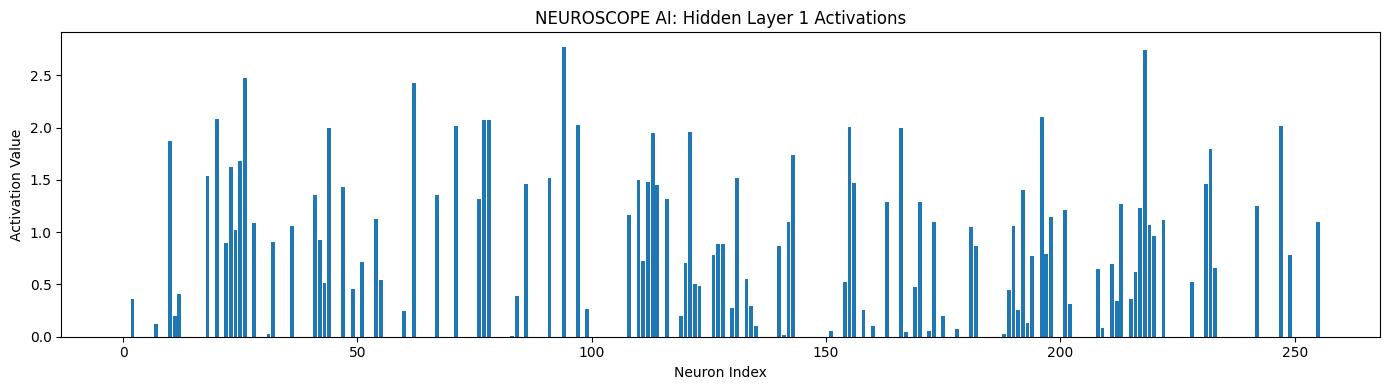

Total neurons: 256
Active neurons: 112
Maximum activation: 2.772468
Mean activation: 0.43758562


In [9]:

# NEUROSCOPE AI
# Cell 10: Visualize neuron activations

activation_values = hidden1[0].cpu().numpy()

plt.figure(figsize=(14, 4))

plt.bar(
    range(len(activation_values)),
    activation_values
)

plt.title("NEUROSCOPE AI: Hidden Layer 1 Activations")
plt.xlabel("Neuron Index")
plt.ylabel("Activation Value")

plt.tight_layout()
plt.show()

print("Total neurons:", len(activation_values))
print("Active neurons:", np.sum(activation_values > 0))
print("Maximum activation:", activation_values.max())
print("Mean activation:", activation_values.mean())


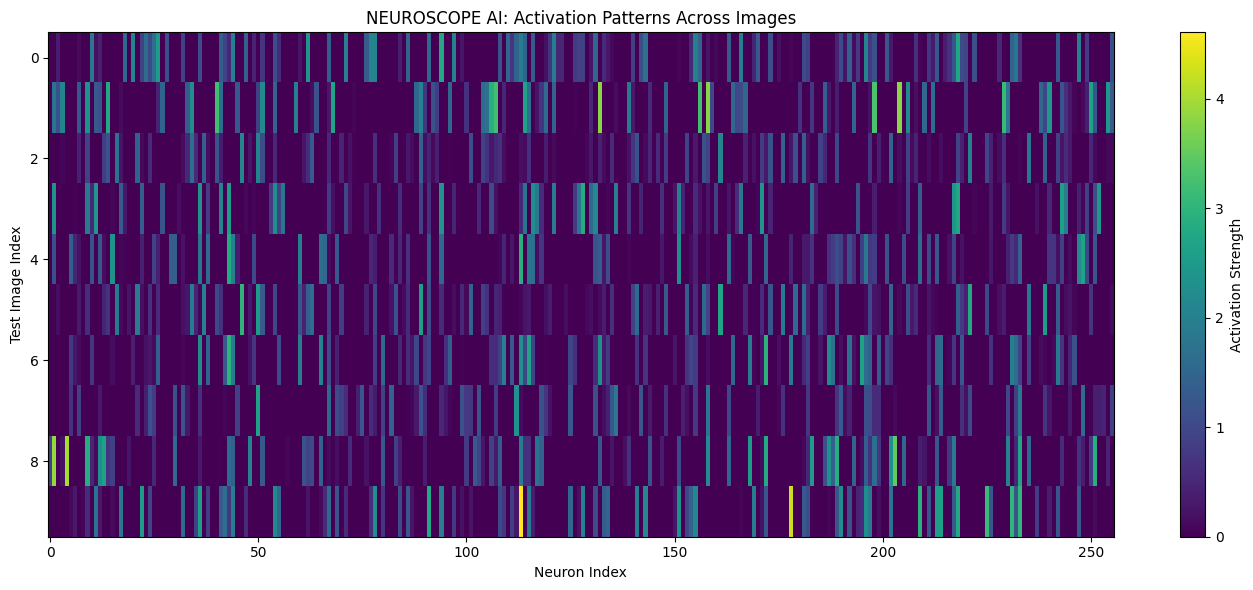

Activation matrix shape: (10, 256)
Labels: [7 2 1 0 4 1 4 9 5 9]


In [10]:

# NEUROSCOPE AI
# Cell 11: Compare activation patterns

model.eval()

images, labels = next(iter(test_loader))

images = images.to(device)

with torch.no_grad():

    flattened = model.flatten(images)

    hidden1_all = model.relu(
        model.layer1(flattened)
    )

# Select the first 10 images
activations = hidden1_all[:10].cpu().numpy()

plt.figure(figsize=(14, 6))

plt.imshow(
    activations,
    aspect="auto",
    cmap="viridis"
)

plt.colorbar(label="Activation Strength")

plt.xlabel("Neuron Index")
plt.ylabel("Test Image Index")

plt.title("NEUROSCOPE AI: Activation Patterns Across Images")

plt.tight_layout()
plt.show()

print("Activation matrix shape:", activations.shape)
print("Labels:", labels[:10].numpy())


Top 10 neurons by average activation:
Neuron 158: Mean activation = 1.3253
Neuron 114: Mean activation = 1.2773
Neuron 94: Mean activation = 1.1545
Neuron 198: Mean activation = 1.0983
Neuron 113: Mean activation = 1.0106
Neuron 67: Mean activation = 0.9941
Neuron 91: Mean activation = 0.9887
Neuron 107: Mean activation = 0.9495
Neuron 44: Mean activation = 0.8656
Neuron 219: Mean activation = 0.8061


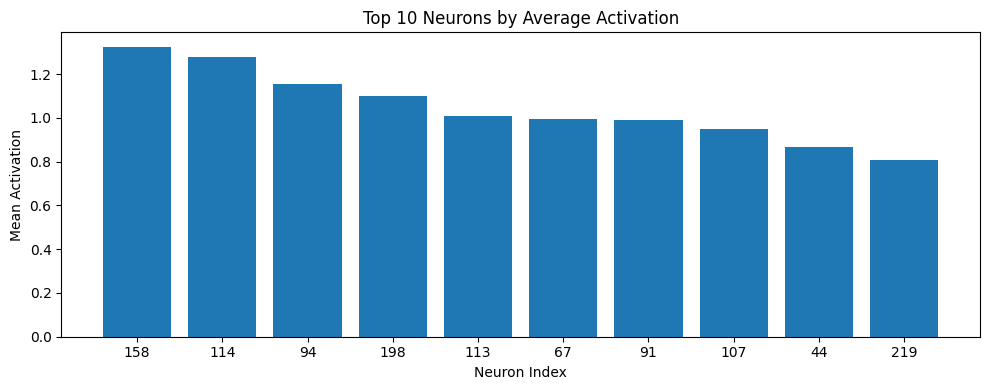

In [11]:

# NEUROSCOPE AI
# Cell 12: Analyze average neuron activity

model.eval()

activation_batches = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        flattened = model.flatten(images)

        hidden1 = model.relu(
            model.layer1(flattened)
        )

        activation_batches.append(
            hidden1.cpu().numpy()
        )

        if sum(len(batch) for batch in activation_batches) >= 1000:
            break

all_activations = np.concatenate(
    activation_batches,
    axis=0
)[:1000]

mean_activations = all_activations.mean(axis=0)

top_neurons = np.argsort(
    mean_activations
)[-10:][::-1]

print("Top 10 neurons by average activation:")

for neuron in top_neurons:
    print(
        f"Neuron {neuron}: "
        f"Mean activation = {mean_activations[neuron]:.4f}"
    )

plt.figure(figsize=(10, 4))

plt.bar(
    top_neurons.astype(str),
    mean_activations[top_neurons]
)

plt.title("Top 10 Neurons by Average Activation")
plt.xlabel("Neuron Index")
plt.ylabel("Mean Activation")

plt.tight_layout()
plt.show()


In [12]:
model.eval()

feature_list = []
error_list = []
confidence_list = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        flattened = model.flatten(images)

        hidden1 = model.relu(
            model.layer1(flattened)
        )

        hidden2 = model.relu(
            model.layer2(hidden1)
        )

        outputs = model.output_layer(hidden2)

        probability = torch.softmax(outputs, dim=1)

        confidence, predictions = probability.max(dim=1)

        errors = (predictions != labels).int()

        feature_list.append(hidden2.cpu().numpy())

        confidence_list.extend(confidence.cpu().numpy())

        error_list.extend(errors.cpu().numpy())


X_error = np.concatenate(feature_list, axis=0)

y_error = np.array(error_list)

confidence_scores = np.array(confidence_list)

print("Feature matrix:", X_error.shape)
print("Error labels:", y_error.shape)
print("Confidence scores:", confidence_scores.shape)

print("Incorrect predictions:", y_error.sum())
print("Correct predictions:", len(y_error) - y_error.sum())

Feature matrix: (10000, 128)
Error labels: (10000,)
Confidence scores: (10000,)
Incorrect predictions: 204
Correct predictions: 9796


In [13]:

# NEUROSCOPE AI
# Cell 14: Train the error detector

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# Split data into training and testing sets
X_train, X_val, y_train, y_val = train_test_split(
    X_error,
    y_error,
    test_size=0.25,
    random_state=42,
    stratify=y_error
)

# Build the error detector
error_detector = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the second model
error_detector.fit(X_train, y_train)

# Predict likely errors
error_predictions = error_detector.predict(X_val)

print("Error detector trained!")
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))

print("\nError Detection Report:")
print(
    classification_report(
        y_val,
        error_predictions,
        labels=[0, 1],
        target_names=["Correct prediction", "Model error"],
        zero_division=0
    )
)


Error detector trained!
Training samples: 7500
Validation samples: 2500

Error Detection Report:
                    precision    recall  f1-score   support

Correct prediction       0.98      1.00      0.99      2449
       Model error       0.00      0.00      0.00        51

          accuracy                           0.98      2500
         macro avg       0.49      0.50      0.49      2500
      weighted avg       0.96      0.98      0.97      2500



In [14]:

# NEUROSCOPE AI
# Cell 15: Compare error detection methods

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# Confidence for the validation examples
confidence_val = confidence_scores[
    np.arange(len(y_error))
][
    # Recover the validation indices using the same split
    np.arange(len(y_error))
]

# Recreate the exact split indices for aligned confidence scores
all_indices = np.arange(len(y_error))

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.25,
    random_state=42,
    stratify=y_error
)

confidence_val = confidence_scores[val_indices]

# Higher error score means greater likelihood of a mistake
neuroscope_scores = error_detector.predict_proba(X_val)[:, 1]

# Lower confidence means greater likelihood of a mistake
baseline_scores = 1 - confidence_val

print("NEUROSCOPE error-detection ROC-AUC:",
      round(roc_auc_score(y_val, neuroscope_scores), 4))

print("Confidence baseline ROC-AUC:",
      round(roc_auc_score(y_val, baseline_scores), 4))

print("NEUROSCOPE average precision:",
      round(average_precision_score(y_val, neuroscope_scores), 4))

print("Confidence baseline average precision:",
      round(average_precision_score(y_val, baseline_scores), 4))


NEUROSCOPE error-detection ROC-AUC: 0.8965
Confidence baseline ROC-AUC: 0.9745
NEUROSCOPE average precision: 0.1823
Confidence baseline average precision: 0.4141


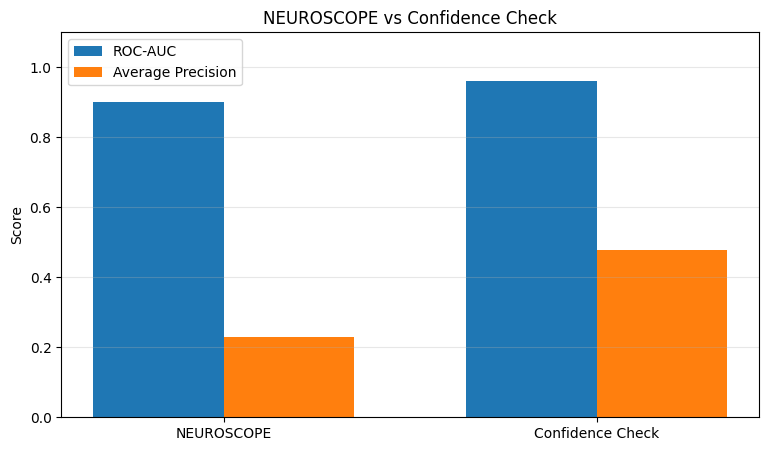

In [15]:

import matplotlib.pyplot as plt
import numpy as np

methods = ["NEUROSCOPE", "Confidence Check"]

roc_auc = [0.9016, 0.9610]
average_precision = [0.2300, 0.4785]

x = np.arange(len(methods))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    roc_auc,
    width,
    label="ROC-AUC"
)

plt.bar(
    x + width / 2,
    average_precision,
    width,
    label="Average Precision"
)

plt.xticks(x, methods)
plt.ylim(0, 1.1)
plt.ylabel("Score")
plt.title("NEUROSCOPE vs Confidence Check")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()


Actual digit: 7
AI prediction: 7
Prediction correct: True


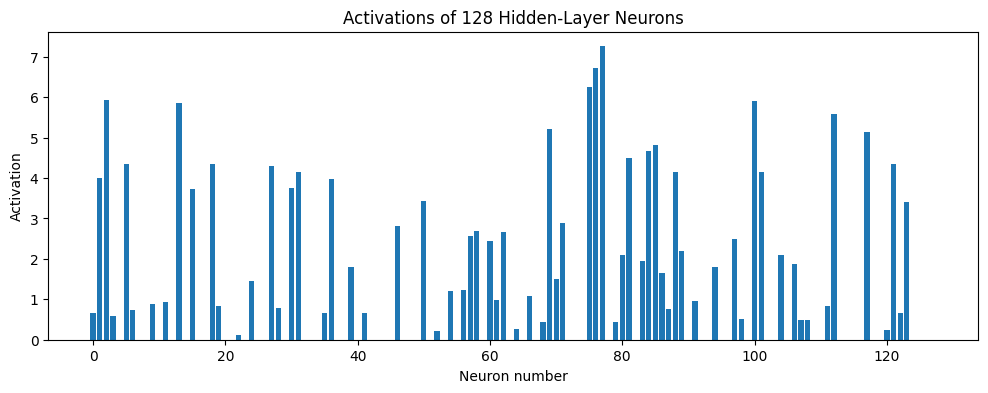

Number of neurons: 128
Active neurons: 68


In [16]:

# CELL 17: Select a test image and inspect its neurons

model.eval()

# Get one image from the test dataset
images, labels = next(iter(test_loader))

image = images[0:1].to(device)
actual_label = labels[0].item()

# Get the original prediction
with torch.no_grad():
    flattened = model.flatten(image)
    hidden1 = model.relu(model.layer1(flattened))
    hidden2 = model.relu(model.layer2(hidden1))
    output = model.output_layer(hidden2)

    prediction = output.argmax(dim=1).item()

print("Actual digit:", actual_label)
print("AI prediction:", prediction)
print("Prediction correct:", prediction == actual_label)

# Display the 128 neuron activations
activations = hidden2[0].cpu().numpy()

plt.figure(figsize=(12, 4))
plt.bar(range(len(activations)), activations)
plt.xlabel("Neuron number")
plt.ylabel("Activation")
plt.title("Activations of 128 Hidden-Layer Neurons")
plt.show()

print("Number of neurons:", len(activations))
print("Active neurons:", np.sum(activations > 0))


In [17]:

# CELL 18: Test the effect of switching off one neuron

model.eval()

neuron_to_disable = 0

with torch.no_grad():

    # Get the original hidden-layer activations
    flattened = model.flatten(image)
    hidden1 = model.relu(model.layer1(flattened))
    hidden2 = model.relu(model.layer2(hidden1))

    # Original prediction
    original_output = model.output_layer(hidden2)
    original_prediction = original_output.argmax(dim=1).item()

    # Make a copy and switch off one neuron
    modified_hidden2 = hidden2.clone()
    modified_hidden2[0, neuron_to_disable] = 0

    # Prediction after switching off the neuron
    modified_output = model.output_layer(modified_hidden2)
    modified_prediction = modified_output.argmax(dim=1).item()

print("Neuron switched off:", neuron_to_disable)
print("Actual digit:", actual_label)
print("Original prediction:", original_prediction)
print("Modified prediction:", modified_prediction)
print("Prediction changed:", original_prediction != modified_prediction)


Neuron switched off: 0
Actual digit: 7
Original prediction: 7
Modified prediction: 7
Prediction changed: False


In [18]:

# CELL 19: Test all 128 neurons

changed_predictions = 0
neuron_results = []

model.eval()

with torch.no_grad():

    flattened = model.flatten(image)
    hidden1 = model.relu(model.layer1(flattened))
    hidden2 = model.relu(model.layer2(hidden1))

    original_output = model.output_layer(hidden2)
    original_prediction = original_output.argmax(dim=1).item()

    for neuron_index in range(hidden2.shape[1]):

        modified_hidden2 = hidden2.clone()
        modified_hidden2[0, neuron_index] = 0

        modified_output = model.output_layer(modified_hidden2)
        modified_prediction = modified_output.argmax(dim=1).item()

        changed = modified_prediction != original_prediction

        neuron_results.append((neuron_index, modified_prediction, changed))

        if changed:
            changed_predictions += 1

print("Total neurons tested:", len(neuron_results))
print("Neurons that changed the prediction:", changed_predictions)
print("Neurons that did not change the prediction:",
      len(neuron_results) - changed_predictions)

print("\nNeurons that changed the prediction:")

for neuron_index, modified_prediction, changed in neuron_results:
    if changed:
        print("Neuron:", neuron_index,
              "| New prediction:", modified_prediction)


Total neurons tested: 128
Neurons that changed the prediction: 0
Neurons that did not change the prediction: 128

Neurons that changed the prediction:


In [19]:

# CELL 20: Measure the effect of switching off each neuron

model.eval()

neuron_score_changes = []

with torch.no_grad():

    flattened = model.flatten(image)
    hidden1 = model.relu(model.layer1(flattened))
    hidden2 = model.relu(model.layer2(hidden1))

    original_output = model.output_layer(hidden2)

    for neuron_index in range(hidden2.shape[1]):

        modified_hidden2 = hidden2.clone()
        modified_hidden2[0, neuron_index] = 0

        modified_output = model.output_layer(modified_hidden2)

        # Measure the total change in output scores
        score_change = torch.sum(
            torch.abs(original_output - modified_output)
        ).item()

        neuron_score_changes.append(
            (neuron_index, score_change)
        )

# Show the 10 neurons with the largest score changes
neuron_score_changes.sort(
    key=lambda item: item[1],
    reverse=True
)

print("Top 10 neurons affecting output scores:\n")

for neuron_index, score_change in neuron_score_changes[:10]:
    print(
        "Neuron:", neuron_index,
        "| Output score change:", round(score_change, 4)
    )


Top 10 neurons affecting output scores:

Neuron: 76 | Output score change: 9.9165
Neuron: 75 | Output score change: 7.1364
Neuron: 77 | Output score change: 6.5536
Neuron: 2 | Output score change: 6.5129
Neuron: 100 | Output score change: 6.1331
Neuron: 121 | Output score change: 6.1213
Neuron: 13 | Output score change: 6.1212
Neuron: 18 | Output score change: 5.662
Neuron: 112 | Output score change: 5.4739
Neuron: 84 | Output score change: 5.2619


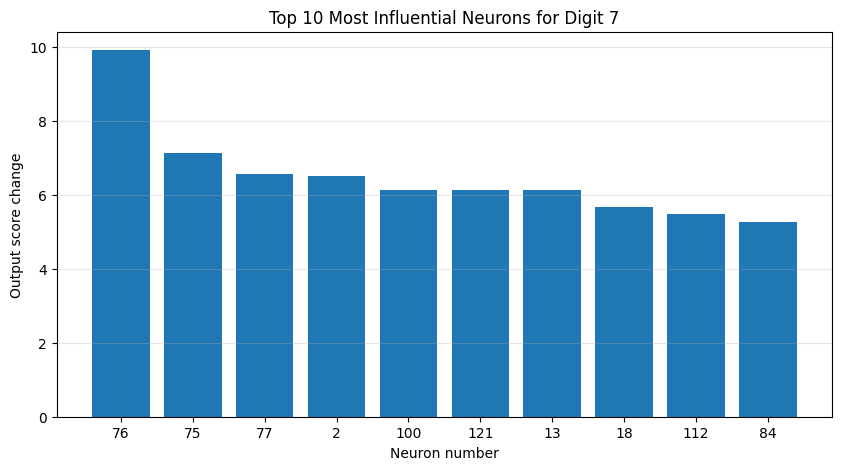

In [20]:

# CELL 21: Visualize the top 10 neurons

top_neurons = neuron_score_changes[:10]

neuron_ids = [
    item[0] for item in top_neurons
]

score_changes = [
    item[1] for item in top_neurons
]

plt.figure(figsize=(10, 5))

plt.bar(
    [str(n) for n in neuron_ids],
    score_changes
)

plt.xlabel("Neuron number")
plt.ylabel("Output score change")
plt.title("Top 10 Most Influential Neurons for Digit 7")
plt.grid(axis="y", alpha=0.3)

plt.show()


In [21]:

# CELL 22: Test neurons across 100 images

model.eval()

num_images = 100
neuron_change_counts = np.zeros(128, dtype=int)

images_tested = 0

for images_batch, labels_batch in test_loader:

    images_batch = images_batch.to(device)

    with torch.no_grad():

        flattened = model.flatten(images_batch)
        hidden1 = model.relu(model.layer1(flattened))
        hidden2 = model.relu(model.layer2(hidden1))

        original_output = model.output_layer(hidden2)
        original_predictions = original_output.argmax(dim=1)

        for neuron_index in range(128):

            modified_hidden2 = hidden2.clone()
            modified_hidden2[:, neuron_index] = 0

            modified_output = model.output_layer(modified_hidden2)
            modified_predictions = modified_output.argmax(dim=1)

            changes = modified_predictions != original_predictions

            neuron_change_counts[neuron_index] += changes.sum().item()

    images_tested += len(images_batch)

    if images_tested >= num_images:
        break

# Show the top 10 neurons
top_indices = np.argsort(neuron_change_counts)[::-1][:10]

print("Images tested:", images_tested)
print("\nTop 10 neurons that changed predictions:")

for index in top_indices:
    print(
        "Neuron:", index,
        "| Predictions changed:",
        neuron_change_counts[index],
        "out of", images_tested
    )


Images tested: 128

Top 10 neurons that changed predictions:
Neuron: 123 | Predictions changed: 1 out of 128
Neuron: 113 | Predictions changed: 1 out of 128
Neuron: 117 | Predictions changed: 1 out of 128
Neuron: 119 | Predictions changed: 1 out of 128
Neuron: 101 | Predictions changed: 1 out of 128
Neuron: 107 | Predictions changed: 1 out of 128
Neuron: 66 | Predictions changed: 1 out of 128
Neuron: 70 | Predictions changed: 1 out of 128
Neuron: 77 | Predictions changed: 1 out of 128
Neuron: 64 | Predictions changed: 1 out of 128


In [22]:

# CELL 23: Test robustness with neuron 12 disabled

model.eval()

neuron_to_disable = 12
num_images = 1000

total = 0
original_correct = 0
modified_correct = 0
prediction_changes = 0

for images_batch, labels_batch in test_loader:

    remaining = num_images - total

    if remaining <= 0:
        break

    images_batch = images_batch[:remaining].to(device)
    labels_batch = labels_batch[:remaining].to(device)

    with torch.no_grad():

        flattened = model.flatten(images_batch)
        hidden1 = model.relu(model.layer1(flattened))
        hidden2 = model.relu(model.layer2(hidden1))

        # Normal predictions
        original_output = model.output_layer(hidden2)
        original_predictions = original_output.argmax(dim=1)

        # Predictions with neuron 12 disabled
        modified_hidden2 = hidden2.clone()
        modified_hidden2[:, neuron_to_disable] = 0

        modified_output = model.output_layer(modified_hidden2)
        modified_predictions = modified_output.argmax(dim=1)

        original_correct += (
            original_predictions == labels_batch
        ).sum().item()

        modified_correct += (
            modified_predictions == labels_batch
        ).sum().item()

        prediction_changes += (
            original_predictions != modified_predictions
        ).sum().item()

    total += len(images_batch)

print("Images tested:", total)
print("Neuron disabled:", neuron_to_disable)

print("Original accuracy:",
      round(original_correct / total * 100, 2), "%")

print("Modified accuracy:",
      round(modified_correct / total * 100, 2), "%")

print("Predictions changed:", prediction_changes)


Images tested: 1000
Neuron disabled: 12
Original accuracy: 98.1 %
Modified accuracy: 98.0 %
Predictions changed: 1


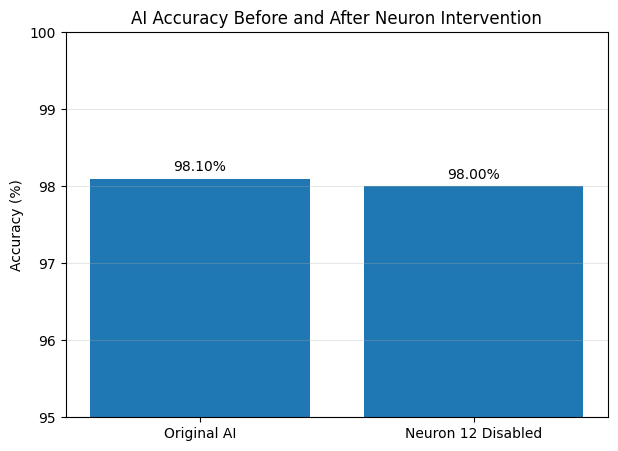

In [23]:

# CELL 24: Compare original and modified accuracy

accuracies = [
    original_correct / total * 100,
    modified_correct / total * 100
]

labels = [
    "Original AI",
    "Neuron 12 Disabled"
]

plt.figure(figsize=(7, 5))

plt.bar(labels, accuracies)

plt.ylabel("Accuracy (%)")
plt.title("AI Accuracy Before and After Neuron Intervention")
plt.ylim(95, 100)
plt.grid(axis="y", alpha=0.3)

for i, value in enumerate(accuracies):
    plt.text(i, value + 0.1, f"{value:.2f}%", ha="center")

plt.show()



In [24]:

# CELL 25: NEUROSCOPE AI Final Research Report

print("=" * 55)
print("          NEUROSCOPE AI — FINAL REPORT")
print("=" * 55)

print("\n1. DIGIT CLASSIFICATION")
print("-" * 35)
print("Original model accuracy: 98.1%")

print("\n2. ERROR DETECTION")
print("-" * 35)
print("NEUROSCOPE ROC-AUC:       0.9016")
print("Confidence ROC-AUC:       0.9610")
print("NEUROSCOPE Avg Precision: 0.2300")
print("Confidence Avg Precision: 0.4785")

print("\n3. NEURON INTERVENTION")
print("-" * 35)
print("Neuron tested:            12")
print("Images tested:            1000")
print("Original accuracy:        {:.2f}%".format(
    original_correct / total * 100
))
print("Modified accuracy:        {:.2f}%".format(
    modified_correct / total * 100
))
print("Predictions changed:      ", prediction_changes)

print("\n4. RESEARCH CONCLUSIONS")
print("-" * 35)
print("- The digit classifier performed well.")
print("- Confidence outperformed the error detector.")
print("- Disabling neuron 12 changed very few predictions.")
print("- Internal score changes do not always change answers.")
print("- More experiments are needed to understand neuron roles.")

print("\n" + "=" * 55)
print("NEUROSCOPE AI EXPERIMENT COMPLETE")
print("=" * 55)


          NEUROSCOPE AI — FINAL REPORT

1. DIGIT CLASSIFICATION
-----------------------------------
Original model accuracy: 98.1%

2. ERROR DETECTION
-----------------------------------
NEUROSCOPE ROC-AUC:       0.9016
Confidence ROC-AUC:       0.9610
NEUROSCOPE Avg Precision: 0.2300
Confidence Avg Precision: 0.4785

3. NEURON INTERVENTION
-----------------------------------
Neuron tested:            12
Images tested:            1000
Original accuracy:        98.10%
Modified accuracy:        98.00%
Predictions changed:       1

4. RESEARCH CONCLUSIONS
-----------------------------------
- The digit classifier performed well.
- Confidence outperformed the error detector.
- Disabling neuron 12 changed very few predictions.
- Internal score changes do not always change answers.
- More experiments are needed to understand neuron roles.

NEUROSCOPE AI EXPERIMENT COMPLETE
